# Location Analysis
#### Sarah Pfalzer, Sunniva Kinnerud

In [1]:
import numpy as np
import scipy
import matplotlib.pyplot as plt
from tabulate import tabulate


## Theoretical foundation

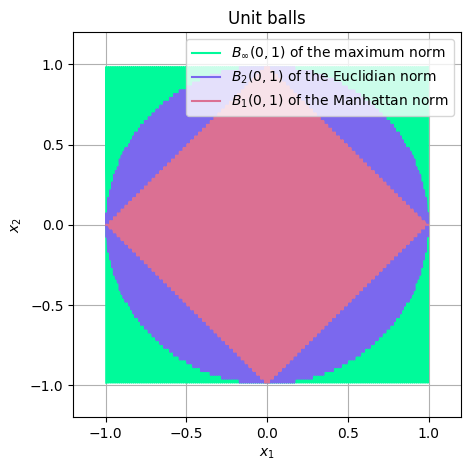

In [2]:
# Finding and plotting unit balls for Manhattan norm, Euclidean norm and maximum norm
min, max = -1.2, 1.2
xs, ys = np.linspace(min, max, 201), np.linspace(min, max, 101)
unit_ball = [[], [], []]
order = [1, 2, np.inf]

for o in range(3):
    for x in xs:
        for y in ys:
            norm = np.linalg.norm((x,y), order[o])
            if norm <= 1:
                unit_ball[o].append((x,y))

x1 = [u[0] for u in unit_ball[0]]
y1 = [u[1] for u in unit_ball[0]]
x2 = [u[0] for u in unit_ball[1]]
y2 = [u[1] for u in unit_ball[1]]
x3 = [u[0] for u in unit_ball[2]]
y3 = [u[1] for u in unit_ball[2]]

figure = plt.figure(figsize=(5, 5))
plt.plot(x3, y3, label = r"$B_{\infty}(0,1)$ of the maximum norm", color="mediumspringgreen")
plt.plot(x2, y2, label = r"$B_2(0,1)$ of the Euclidian norm", color="mediumslateblue")
plt.plot(x1, y1, label = r"$B_1(0,1)$ of the Manhattan norm", color="palevioletred")
plt.axis([min, max, min, max])
plt.title("Unit balls")
plt.xlabel(r"$x_1$")
plt.ylabel(r"$x_2$")
plt.grid()
plt.legend()
plt.show()


## The Weiszfeld Algorithm

In [3]:
def termination_ratio(x, A, v):
    """
    Finds the ratio UB/LB used in the termination criterion derived in the report

    Parameters
    ----------
    :x: ndarray, location at the current iterate
    :A: ndarray, given locations
    :v: ndarray, given weights corresponding to the given locations

    Returns
    -------
    :ratio: float, the ratio UB/LB
    """
    M = np.arange(len(v))       # Indexes for given locations
    fd2 = 0
    grad_fd2 = np.zeros(2)

    for i in M:
        d2 = np.linalg.norm(A[i] - x)       # Euclidean distance
        fd2 += v[i] * d2
        # Avoid zerodivision
        if d2 > 1e-12:
            grad_fd2 += v[i] * (x - A[i]) / d2

    convex_hull = scipy.spatial.ConvexHull(A)
    ys = A[convex_hull.vertices]
    sigma = np.max([np.linalg.norm(x - y) for y in ys])
    ratio = np.linalg.norm(grad_fd2) * sigma / (fd2 - np.linalg.norm(grad_fd2) * sigma)

    return np.abs(ratio)


In [4]:
def weiszfeld(A, v, eps, startpoint_mean):
    """
    Solves the Median problem with weighted Euclidean distances with the Weiszfeld algorithm

    Parameters
    ----------
    :A: ndarray, given locations
    :v: ndarray, given weights corresponding to the given locations
    :eps: float, relative accuracy

    Returns
    -------
    :x_star: ndarray, minimiser found by the algorithm
    :loops: int, number of loops of the main iteration scheme
    """
    loops = 0
    m = len(v)      # Number of given weights, i.e. number of given locations
    M = np.arange(m)        # Indexes for given locations
    
    # a) Checking if minimum is attained at existing location a^i
    k = M[0] - 1
    test_k = np.inf
    vk = v[k]

    # Checking whether Test_k <= v^k, and also that we do not go out of range
    while(test_k > vk and k < m - 1):
        k += 1
        sum1, sum2 = 0, 0
        indices = M
        indices = np.delete(indices, np.where(indices == k))        # Deleting the indice i
        
        for i in indices:
            d2 = np.linalg.norm(A[k] - A[i])        # Euclidean distance

            # Avoid zerodivision
            if d2 > 1e-12:
                sum1 += v[i] * (A[k, 0] - A[i, 0]) / d2
                sum2 += v[i] * (A[k, 1] - A[i, 1]) / d2

        test_k = np.sqrt((sum1)**2 + (sum2)**2)
        vk = v[k]

    # Returns solution and zero loops if minimiser is found at existing location
    if test_k <= vk:
        x_star = A[k]
        return x_star, loops

    # b) Choosing a starting point x=(x1,x2) by solving median problem w/squared euclidian distance
    if startpoint_mean:
        x = np.array([1/m * np.sum(A[:, 0]), 1/m * np.sum(A[:, 1])])
    else:
        x = np.array([2,2])

    # ratio = np.inf
    ratio = termination_ratio(x, A, v)

    # Keeps iterating with the main iteration scheme while termination criterion is not fulfilled
    while(ratio >= eps):
        # c) Set xj^new
        numerator1, numerator2, denominator = 0, 0, 0
        
        for i in M:
            d2 = np.linalg.norm(A[i] - x)

            if d2 > 1e-12:
                numerator1 += v[i] * A[i, 0] / d2
                numerator2 += v[i] * A[i, 1] / d2
                denominator += v[i] / d2

        x = np.array([numerator1 / denominator, numerator2 / denominator])      # New location for x
        
        # d) Termination criterion
        ratio = termination_ratio(x, A, v)
        
        loops += 1

    x_star = x
    return x_star, loops


In [5]:
def gradient_descent(A, v, eps, startpoint_mean):
    """
    Solves the Median problem with weighted Euclidean distances with Gradient Descent with backtracking

    Parameters
    ----------
    :A: ndarray, given locations
    :v: ndarray, given weights corresponding to the given locations
    :eps: float, relative accuracy

    Returns
    -------
    :x_star: ndarray, minimiser found by the algorithm
    :loops_outer: int, number of loops of the main iteration scheme
    :loops_inner: int, number of operations of the main iteration scheme, including the line search
    """
    loops_outer = 0
    loops_inner = 0
    m = len(v)      # Number of given weight, i.e. number of given locations
    M = np.arange(m)        # Indexes of given locations
    
    # a) Checking if minimum is attained at existing location a^i
    k = M[0] - 1
    test_k = np.inf
    vk = v[k]

    # Checking whether Test_k <= v^k, and also that we do not go out of range
    while(test_k > vk and k < m - 1):
        k += 1
        sum1, sum2 = 0, 0
        indices = M
        indices = np.delete(indices, np.where(indices == k))        # Deleting the indice i
        
        for i in indices:
            d2 = np.linalg.norm(A[k] - A[i])        # Euclidean distance
            sum1 += v[i] * (A[k, 0] - A[i, 0]) / d2
            sum2 += v[i] * (A[k, 1] - A[i, 1]) / d2

        test_k = np.sqrt((sum1)**2 + (sum2)**2)
        vk = v[k]

    # Returns solution and zero loops if minimiser is found at existing location
    if test_k <= vk:
        x_star = A[k]
        return x_star, loops_outer, loops_inner


    # b)-d) Gradient descent replacement
    # b) Choosing a starting point x=(x1,x2) by solving median problem w/squared euclidian distance
    if startpoint_mean:
        x = np.array([1/m * np.sum(A[:, 0]), 1/m * np.sum(A[:, 1])])
    else:
        x = np.array([2,2])
        
    rho = 0.5
    C = 2/3

    def f(x):
        """
        Objective function from the Median problem with weighted Euclidean distances

        Parameters
        ----------
        :x: ndarray, location at the current iterate

        Returns
        -------
        :f: float, objective function evaluated at current location
        """
        f = 0
        for i in M:
            f += v[i] * np.linalg.norm(x - A[i])

        return f

    def grad(x):
        """
        Gradient of objective function from the Median problem with weighted Euclidean distances

        Parameters
        ----------
        :x: ndarray, location at the current iterate

        Returns
        -------
        :grad: ndarray, gradient of objective function evaluated at current location
        """
        grad = np.zeros(2)
        for i in M:
            if np.linalg.norm(x - A[i]) > 1e-12:
                grad += v[i] * (x - A[i]) / np.linalg.norm(x - A[i])

        return grad

    # ratio = np.inf
    ratio = termination_ratio(x, A, v)
    
    # Keeps iterating with the main iteration scheme while termination criterion is not fulfilled
    while(ratio >= eps):
        # c) Set xj^new
        alpha = 0.5
        grad_f = grad(x)
        f_old = f(x)
        f_new = f(x - alpha * grad_f)

        # Backtracking line search with Armijo condition
        while(f_new > f_old - C * alpha * grad_f @ grad_f):
            alpha = rho * alpha
            f_new = f(x - alpha * grad_f)
            loops_inner += 1

        x = x - alpha * grad_f      # New location for x
        loops_outer += 1
        loops_inner += 1

        # d) Termination criterion
        ratio = termination_ratio(x, A, v)

    x_star = x
    return x_star, loops_outer, loops_inner


In [6]:
def plot_weiszfeld(A, v, i, j, eps, axs, equal, title, startpoint_mean):
    """
    Plots given points (with weights) and the minimiser found by Weiszfeld

    Parameters
    ----------
    :A: ndarray, given locations
    :v: ndarray, given weights corresponding to the given locations
    :i: int, indice of first coordinate of subplot
    :j: int, indice of second cooridante of subplot
    :equal: bool, indicates whether all weights are equal or not
    :title: string, title of the subplot
    :eps: float, relative accuracy
    :axs: 

    Returns
    -------
    :iters: int, number of iterations of main iteration shceme
    """
    coord, iters = weiszfeld(A, v, eps, startpoint_mean)
    axs[i,j].grid(alpha = 0.25)
    axs[i,j].plot(A[:,0], A[:,1], 'o', label="Given points", color="mediumslateblue")
    axs[i,j].plot(coord[0], coord[1], 'o', label="Minimiser", color="palevioletred")
    axs[i,j].set_xlabel(r'$x_1$')
    axs[i,j].set_ylabel(r'$x_2$')
    axs[i,j].set_title(title)
    axs[i,j].legend()
    pts = (5, 5)
    axs[i,j].annotate(f'{(float(np.round(coord[0],6)), float(np.round(coord[1],6)))}', xy =(coord[0], coord[1]), fontsize=9, color='palevioletred', xytext=pts, textcoords='offset pixels')

    if not equal:
        for k, a in enumerate(A):
            if a[0] >= np.max(A[:,0]):
                pts = (-40, 5)
            else:
                pts = (5, 5)

            axs[i,j].annotate(f'v = {v[k]}', xy =(a[0], a[1]), fontsize=9, color='mediumslateblue', xytext=pts, textcoords='offset pixels')
    
    return iters


In [7]:
def plot_gradient_descent(A, v, i, j, eps, axs, equal, title, startpoint_mean):
    coord, iters, operations = gradient_descent(A, v, eps, startpoint_mean)
    axs[i,j].grid(alpha = 0.25)
    axs[i,j].plot(A[:,0], A[:,1], 'o', label=r"Set of given points $A$", color="mediumslateblue")
    axs[i,j].plot(coord[0], coord[1], 'o', label="Minimiser", color="palevioletred")        
    axs[i,j].set_xlabel(r'$x_1$')
    axs[i,j].set_ylabel(r'$x_2$')
    axs[i,j].set_title(title)
    axs[i,j].legend()
    pts = (5, 5)
    axs[i,j].annotate(f'{(float(np.round(coord[0],6)), float(np.round(coord[1],6)))}', xy =(coord[0], coord[1]), fontsize=9, color='palevioletred', xytext=pts, textcoords='offset pixels')

    if not equal:
        for k, a in enumerate(A):
            if a[0] >= np.max(A[:,0]):
                pts = (-40, 5)
            else:
                pts = (5, 5)
            axs[i,j].annotate(f'v = {v[k]}', xy =(a[0], a[1]), fontsize=9, color='mediumslateblue', xytext=pts, textcoords='offset pixels')
    return iters, operations


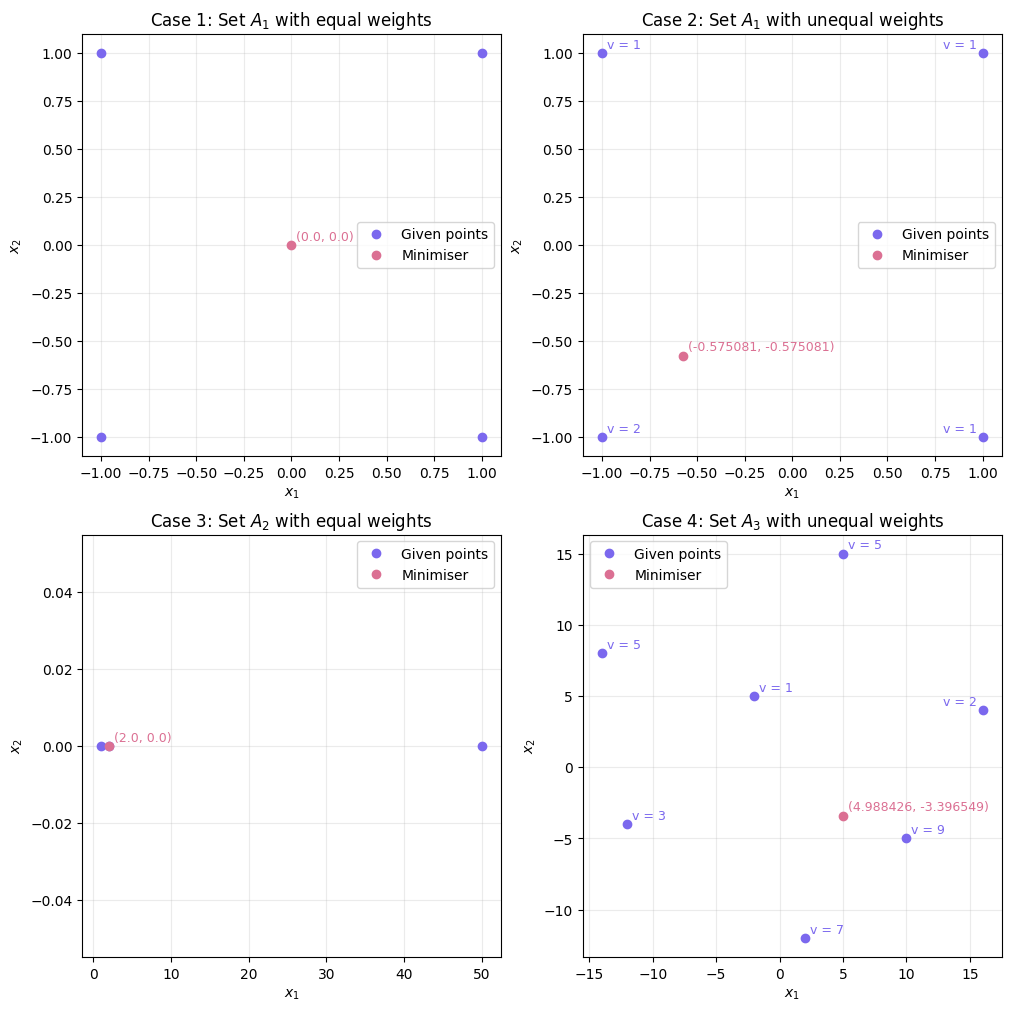

In [8]:
eps = 0.001

iterations_weiszfeld = []
fig, axs = plt.subplots(2, 2, figsize = (10, 10), constrained_layout = True)

A = np.array([[1, 1], [-1, 1], [1, -1], [-1, -1]])
v = np.array([1, 1, 1, 1])
iters= plot_weiszfeld(A, v, 0, 0, eps, axs, True, r'Case 1: Set $A_1$ with equal weights', True)
iterations_weiszfeld.append(iters)

A = np.array([[1, 1], [-1, 1], [1, -1], [-1, -1]])
v = np.array([1, 1, 1, 2])
iters = plot_weiszfeld(A, v, 0, 1, eps, axs, False, r'Case 2: Set $A_1$ with unequal weights', True)
iterations_weiszfeld.append(iters)

A = np.array([[1,0], [2,0], [50,0]])
v = np.array([1, 1, 1])
iters = plot_weiszfeld(A, v, 1, 0, eps, axs, True, r'Case 3: Set $A_2$ with equal weights', True)
iterations_weiszfeld.append(iters)

A = np.array([[-14, 8], [-12, -4], [2, -12], [10, -5], [16, 4], [5, 15], [-2, 5]])
v = np.array([5, 3, 7, 9, 2, 5, 1])
iters = plot_weiszfeld(A, v, 1, 1, eps, axs, False, r'Case 4: Set $A_3$ with unequal weights', True)
iterations_weiszfeld.append(iters)

plt.show()


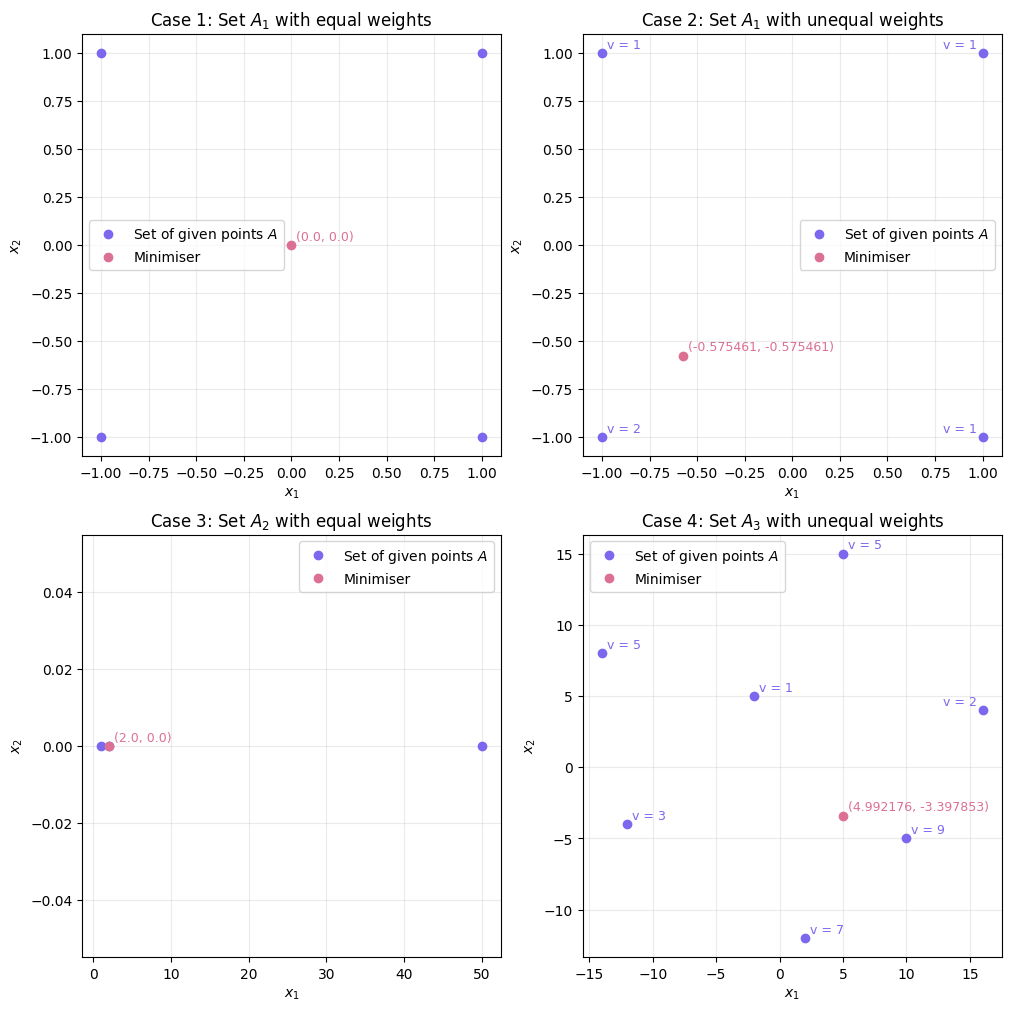

In [9]:
iterations_gradient_descent = []
operations_gradient_descent = []
fig, axs = plt.subplots(2, 2, figsize = (10, 10), constrained_layout = True)

A = np.array([[1, 1], [-1, 1], [1, -1], [-1, -1]])
v = np.array([1, 1, 1, 1])
iters, operations = plot_gradient_descent(A, v, 0, 0, eps, axs, True, r'Case 1: Set $A_1$ with equal weights', True)
iterations_gradient_descent.append(iters)
operations_gradient_descent.append(operations)

A = np.array([[1, 1], [-1, 1], [1, -1], [-1, -1]])
v = np.array([1, 1, 1, 2])
iters, operations = plot_gradient_descent(A, v, 0, 1, eps, axs, False, r'Case 2: Set $A_1$ with unequal weights', True)
iterations_gradient_descent.append(iters)
operations_gradient_descent.append(operations)

A = np.array([[1,0], [2,0], [50,0]])
v = np.array([1, 1, 1])
iters, operations = plot_gradient_descent(A, v, 1, 0, eps, axs, True, r'Case 3: Set $A_2$ with equal weights', True)
iterations_gradient_descent.append(iters)
operations_gradient_descent.append(operations)

A = np.array([[-14, 8], [-12, -4], [2, -12], [10, -5], [16, 4], [5, 15], [-2, 5]])
v = np.array([5, 3, 7, 9, 2, 5, 1])
iters, operations = plot_gradient_descent(A, v, 1, 1, eps, axs, False, r'Case 4: Set $A_3$ with unequal weights', True)
iterations_gradient_descent.append(iters)
operations_gradient_descent.append(operations)

plt.show()


In [10]:
table_arr = np.array([[1,'.','.','.','.','.'], [2,'.','.','.','.','.'], [3,'.','.','.','.','.'], [4,'.','.','.','.','.'], [1,'.','.','.','.','.']])
for i in range(len(table_arr) - 1):
    table_arr[i][1] = "Mean"
    table_arr[i][2] = iterations_weiszfeld[i]
    table_arr[i][3] = iterations_gradient_descent[i]
    table_arr[i][4] = iterations_weiszfeld[i]
    table_arr[i][5] = operations_gradient_descent[i]

A = np.array([[1, 1], [-1, 1], [1, -1], [-1, -1]])
v = np.array([1, 1, 1, 1])

table_arr[4][1] = "(2,2)"

_, iters = weiszfeld(A, v, eps, False)
table_arr[4][2] = iters
table_arr[4][4] = iters

_, iters, operations = gradient_descent(A, v, eps, False)
table_arr[4][3] = iters
table_arr[4][5] = operations

print(tabulate(
    table_arr,
    headers=['Case', 'Starting point', 'Weiszfeld iterations', 'Gradient descent iterations', 'Weiszfeld operations', 'Gradient descent operations'],
    tablefmt='orgtbl'))


|   Case | Starting point   |   Weiszfeld iterations |   Gradient descent iterations |   Weiszfeld operations |   Gradient descent operations |
|--------+------------------+------------------------+-------------------------------+------------------------+-------------------------------|
|      1 | Mean             |                      0 |                             0 |                      0 |                             0 |
|      2 | Mean             |                     23 |                             9 |                     23 |                            10 |
|      3 | Mean             |                      0 |                             0 |                      0 |                             0 |
|      4 | Mean             |                     14 |                             8 |                     14 |                             8 |
|      1 | (2,2)            |                      9 |                            12 |                      9 |                         